# Aligned AR on S7_k02345 — seeds 43 and 44, plus the 3-seed plot

Aligned AR (no sequence position, target-cell coordinates, 10-way digit head) on 7 slots, trained k = 0, 2, 3, 4, 5.
This is the same setting as notebook 34 (seed 42: single operations 1.00, k = 6 0.9996, k = 7 0.985). Only the
seed changes, which affects the initialization and the training stream; the test records are identical.

The two seeds run one after the other (resumable). The last cell plots all three seeds (42, 43, 44). The Standard AR
is included as a reference if its seed runs exist (notebooks 23 / 27).
**Send back `AlignedAR_S7_k02345_3seeds_Review.ipynb`.**


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 390571d53417ae952f9c5a558b2ec767df83fb33


In [2]:
# --- CONFIGURATION -------------------------------------------------------------------------------------------------
MODE = os.environ.get("DECOMP_MODE", "full")
SEEDS = [43, 44]
RUN_CONDITIONS = ['S7_k02345']
RUN_MODELS = ["ar_slotpos_digithead_target"]
STEPS = 20000
SUBDIR = "S7_support_sweep_20k_v1"                # same folder as notebooks 23 / 27 (model subfolders differ)
EVAL_PLAN = {"n_single_grids": 1000, "n_seen_per_k": 5000, "n_long_per_k": 20000}
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import pandas as pd
from IPython.display import display
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
from decompositionality import longk as LK, longk_exp as LX
print("results ->", LX.family_root(RESULTS_ROOT, MODE, SUBDIR))


Mounted at /content/drive
results -> /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1


In [3]:
# --- Train (20,000 updates) + sampled LAST-checkpoint evaluation, seeds 43 and 44 (resumable) -------------------------
for SEED in SEEDS:
    print(f"\n######## seed {SEED} ########")
    status = LX.run_queue(RESULTS_ROOT, MODE, SEED, RUN_CONDITIONS, RUN_MODELS, repo_dir=str(REPO_DIR), device=DEVICE,
                          subdir=SUBDIR, steps=STEPS if MODE == "full" else None, sampled_plan=EVAL_PLAN)
    display(status)



######## seed 43 ########
[S7_k02345] S=7 train k=[0, 2, 3, 4, 5] | val 1500 | manifests bdf24c327a65

=== S7_k02345 / ar_slotpos_digithead_target ===
  microbatch probe: 256 fits
[ar_slotpos_digithead_target] 10,670,218 params | device NVIDIA RTX PRO 6000 Blackwell Server Edition | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 1.5564 (best) | subset(160) exact 0.194 cell 0.358
  step 475/20000 loss 1.0119 lr 3.00e-04 | 23.51 steps/s, 6019 ex/s | ETA 13.8 min
  [val @ 500] cell CE 0.9750 (best) | subset(160) exact 0.219 cell 0.427
  [val @ 750] cell CE 0.5106 (best) | subset(160) exact 0.225 cell 0.557
  step 950/20000 loss 0.3671 lr 2.99e-04 | 23.31 steps/s, 5967 ex/s | ETA 13.6 min
  [val @ 1000] cell CE 0.3207 (best) | subset(160) exact 0.325 cell 0.699
  [val @ 1250] cell CE 0.2064 (best) | subset(160) exact 0.406 cell 0.794
  step 1425/20000 loss 0.1220 lr 2.98e-04 | 23.18 steps/s, 5934 ex/s | ETA 13.4 min
  [val @ 1500] cell CE 0.1174 (best) | subset(1

,condition,model,trained,evaluated_last,records,best_step (reference),complete
0,S7_k02345,ar_slotpos_digithead_target,True,True,82000,20000,True



######## seed 44 ########
[S7_k02345] S=7 train k=[0, 2, 3, 4, 5] | val 1500 | manifests bdf24c327a65

=== S7_k02345 / ar_slotpos_digithead_target ===
  microbatch probe: 256 fits
[ar_slotpos_digithead_target] 10,670,218 params | device NVIDIA RTX PRO 6000 Blackwell Server Edition | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 1.5370 (best) | subset(160) exact 0.212 cell 0.373
  step 500/20000 loss 1.1035 lr 3.00e-04 | 24.49 steps/s, 6271 ex/s | ETA 13.3 min
  [val @ 500] cell CE 1.1456 (best) | subset(160) exact 0.212 cell 0.393
  [val @ 750] cell CE 0.6852 (best) | subset(160) exact 0.212 cell 0.481
  step 975/20000 loss 0.4398 lr 2.99e-04 | 23.92 steps/s, 6123 ex/s | ETA 13.3 min
  [val @ 1000] cell CE 0.4377 (best) | subset(160) exact 0.256 cell 0.614
  [val @ 1250] cell CE 0.2175 (best) | subset(160) exact 0.456 cell 0.755
  step 1450/20000 loss 0.1250 lr 2.98e-04 | 23.69 steps/s, 6065 ex/s | ETA 13.0 min
  [val @ 1500] cell CE 0.1426 (best) | subset(1

,condition,model,trained,evaluated_last,records,best_step (reference),complete
0,S7_k02345,ar_slotpos_digithead_target,True,True,82000,19750,True


# Aligned AR on S7_k02345: 3 seeds [42, 43, 44] (LAST checkpoint, 20,000 updates)
Seeds change the initialization and the training stream; the test records are identical for every seed.


### Availability


,model,seed,status
0,Aligned AR,42,ok
1,Aligned AR,43,ok
2,Aligned AR,44,ok
3,Standard AR,42,ok
4,Standard AR,43,ok
5,Standard AR,44,ok



### Accuracy by test length over seeds


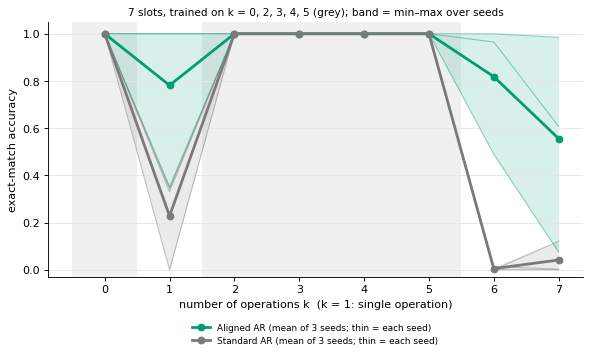


### Held-out accuracy per seed


metric,model,seed,single A,single B,single C,k=6,k=7
0,Aligned AR,42,1.0000,1.0000,1.0000,0.9996,0.9848
1,Aligned AR,43,1.0000,1.0000,1.0000,0.9649,0.6073
2,Aligned AR,44,0.0001,1.0000,0.0321,0.4900,0.0747
3,Standard AR,42,0.0000,0.9916,0.0000,0.0136,0.0024
4,Standard AR,43,0.0000,0.0000,0.0000,0.0000,0.1210
5,Standard AR,44,0.0564,1.0000,0.0000,0.0000,0.0000


REVIEW FILE: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/aligned_ar_S7_k02345_seeds/AlignedAR_S7_k02345_3seeds_Review.ipynb
REVIEW FILE TO SEND BACK: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/aligned_ar_S7_k02345_seeds/AlignedAR_S7_k02345_3seeds_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# --- Three seeds (42, 43, 44): plot + per-seed table ---------------------------------------------------------------
from decompositionality import ar_ablation as AB
rp = AB.plot_seeds(RESULTS_ROOT, MODE, seeds=[42, 43, 44])
print("REVIEW FILE TO SEND BACK:", rp)
if IN_COLAB and rp:
    from google.colab import files
    files.download(str(rp))


In [5]:
from google.colab import runtime

runtime.unassign()